# Study 2 reward comparison

How do local, global, and mixed rewards change development, pollution, spending, and environmental failure?

Current design: nonlinear emissions, prevention-only mitigation with high capacity 20, and economic reward equal to EDI gain plus `(income - base income) / 10`. Action costs, persistence, spillover, pollution penalty, and reward sharing are unchanged.

- Existing outputs and Q-tables are historical. This notebook now trains in a separate results folder so those files remain untouched. Run all cells to train policies under the current design before interpreting its tables.

In [1]:
import json
import random

import matplotlib.pyplot as plt
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig, TrainingConfig
from study_2_economic_sustainability.environment import EconomicSustainabilityEnvironment
from study_2_economic_sustainability.agents import TabularQLearner

## Settings

In [2]:
REWARD_MODES = ("local", "global", "mixed")
TRAINING_SEEDS = (11, 23, 37, 41, 53)
EVALUATION_SEEDS = tuple(range(100_000, 100_020))
TRAINING_EPISODES = 2000
BASELINE_NAMES = ("save", "develop", "mitigate", "coordinate", "random_affordable")
RESULTS_DIRECTORY = "../results/reward_comparison_current"
RUN_TRAINING = True  # Train current-design policies; set False only after these Q-tables exist

environment_config = EnvironmentConfig()
training_config = TrainingConfig()

## Train agents

- Each reward mode has five independent training seeds.
- `train_episode` updates four Q-tables after each environment step.
- The next cell repeats that episode and lowers exploration after each run.

In [3]:
def train_episode(environment, agents, seed):
    observations = environment.reset(seed)

    while True:
        actions = []
        for region in range(4):
            action = agents[region].select_action(observations[region])
            actions.append(action)

        next_observations, rewards, terminated, truncated, info = environment.step(tuple(actions))

        for region in range(4):
            agents[region].update(
                observations[region], actions[region], rewards[region],
                next_observations[region], terminated,
            )

        observations = next_observations
        if terminated or truncated:
            break

In [4]:
trained_agents = {}

if RUN_TRAINING:
    for reward_mode in REWARD_MODES:
        for training_seed in TRAINING_SEEDS:
            environment = EconomicSustainabilityEnvironment(reward_mode, environment_config)
            episode_rng = random.Random(training_seed)
            agents = []

            for region in range(4):
                agents.append(TabularQLearner(training_seed * 10 + region, training_config))

            for episode in range(TRAINING_EPISODES):
                seed = episode_rng.randrange(100_000)
                train_episode(environment, agents, seed)

                for agent in agents:
                    agent.decay_epsilon()

            trained_agents[(reward_mode, training_seed)] = agents
            print(f"Trained {reward_mode}, seed {training_seed}")

## Save or load Q-tables

- With `RUN_TRAINING = True`, save one JSON file for each reward mode and training seed.
- With `RUN_TRAINING = False`, load those files and skip training.

In [ ]:
if RUN_TRAINING:
    for (reward_mode, training_seed), agents in trained_agents.items():
        tables = []

        for agent in agents:
            table = {}
            for observation, values in sorted(agent.q.items()):
                observation_values = []
                for bin_value in observation:
                    observation_values.append(str(bin_value))
                key = ",".join(observation_values)
                table[key] = values
            tables.append(table)

        filename = f"{RESULTS_DIRECTORY}/q_{reward_mode}_{training_seed}.json"
        with open(filename, "w", encoding="utf-8") as file:
            json.dump(tables, file, indent=2)
            file.write("\n")


In [ ]:
if not RUN_TRAINING:
    for reward_mode in REWARD_MODES:
        for training_seed in TRAINING_SEEDS:
            filename = f"{RESULTS_DIRECTORY}/q_{reward_mode}_{training_seed}.json"
            with open(filename, "r", encoding="utf-8") as file:
                tables = json.load(file)

            if len(tables) != 4:
                raise ValueError("A saved policy must contain four Q-tables")

            agents = []
            for region, table in enumerate(tables):
                agent = TabularQLearner(region, training_config)
                for key, values in table.items():
                    observation_values = []
                    for bin_value in key.split(","):
                        observation_values.append(int(bin_value))
                    observation = tuple(observation_values)
                    agent.q[observation] = values
                agents.append(agent)

            trained_agents[(reward_mode, training_seed)] = agents


## Measure an evaluation episode

- Choose greedy actions for learned agents or follow one baseline rule.
- Add GPI, mitigation spending, and invalid attempts after each step.
- Return one row of common outcome measures when the episode ends.

In [7]:
def choose_evaluation_actions(environment, observations, agents, rule, policy_rng):
    if agents is None:
        return rule(environment, observations, policy_rng)

    actions = []
    for region in range(4):
        action = agents[region].select_action(observations[region], greedy=True)
        actions.append(action)

    return tuple(actions)

In [8]:
def add_step_measurements(totals, actions, info):
    totals["gpi"] += info["global_pollution_index"]
    totals["invalid_attempts"] += sum(info["invalid_attempts"])

    for region in range(4):
        if actions[region] in (2, 3, 4):
            totals["mitigation_spending"] += info["costs_paid"][region]

In [9]:
def evaluate_episode(environment, seed, agents=None, rule=None, policy_rng=None):
    observations = environment.reset(seed)
    totals = {"gpi": 0.0, "mitigation_spending": 0.0, "invalid_attempts": 0}

    while True:
        actions = choose_evaluation_actions(environment, observations, agents, rule, policy_rng)
        observations, rewards, terminated, truncated, info = environment.step(actions)
        add_step_measurements(totals, actions, info)

        if terminated or truncated:
            break

    return {
        "steps": environment.step_count,
        "terminated": terminated,
        "mean_gpi": totals["gpi"] / environment.step_count,
        "mean_final_edi": sum(environment.development_indices) / 4,
        "mitigation_spending": totals["mitigation_spending"],
        "invalid_attempts": totals["invalid_attempts"],
    }

## Evaluate learned agents

- Use the same 20 held-out environment seeds for every trained policy.
- Add the reward mode and training seed to each episode row.
- Evaluation does not call the Q-learning update.

In [10]:
evaluation_rows = []

for reward_mode in REWARD_MODES:
    for training_seed in TRAINING_SEEDS:
        agents = trained_agents[(reward_mode, training_seed)]
        environment = EconomicSustainabilityEnvironment(reward_mode, environment_config)

        for seed in EVALUATION_SEEDS:
            row = evaluate_episode(environment, seed, agents=agents)
            row["policy"] = reward_mode
            row["training_seed"] = training_seed
            row["environment_seed"] = seed
            evaluation_rows.append(row)

        print(f"Evaluated {reward_mode}, training seed {training_seed}")

Evaluated local, training seed 11
Evaluated local, training seed 23
Evaluated local, training seed 37
Evaluated local, training seed 41
Evaluated local, training seed 53
Evaluated global, training seed 11
Evaluated global, training seed 23
Evaluated global, training seed 37
Evaluated global, training seed 41
Evaluated global, training seed 53
Evaluated mixed, training seed 11
Evaluated mixed, training seed 23
Evaluated mixed, training seed 37
Evaluated mixed, training seed 41
Evaluated mixed, training seed 53


In [11]:
evaluations = pd.DataFrame(evaluation_rows)
evaluations.to_csv(f"{RESULTS_DIRECTORY}/evaluation_episodes.csv", index=False)

## Simple baselines

- These five rules face the same held-out starting balances as the learned agents.
- Random affordable uses its own action seed.
- The rules avoid unaffordable actions and learned agents can still attempt them and receive a penalty.

### Save and develop

- Save spends nothing.
- Develop buys action 1 when affordable and EDI is below 100.

In [12]:
def save_policy(environment, observations, rng):
    return (0, 0, 0, 0)


def develop_policy(environment, observations, rng):
    actions = []
    cost = environment.config.action_costs[1]

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        if edi < 100 and balance >= cost:
            actions.append(1)
        else:
            actions.append(0)

    return tuple(actions)

### Mitigate

- Choose the strongest mitigation action the region can afford.

In [13]:
def strongest_affordable_mitigation(balance, costs):
    for action in (4, 3, 2):
        if balance >= costs[action]:
            return action

    return 0


def mitigate_policy(environment, observations, rng):
    actions = []

    for balance in environment.currency_balances:
        action = strongest_affordable_mitigation(balance, environment.config.action_costs)
        actions.append(action)

    return tuple(actions)

### Coordinate

- Mitigate when local or shared pollution rises above the lowest bin.
- Otherwise, develop up to EDI 70 when affordable.

In [14]:
def coordinate_policy(environment, observations, rng):
    actions = []
    costs = environment.config.action_costs

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        local_bin = observations[region][2]
        global_bin = observations[region][3]

        if local_bin >= 1 or global_bin >= 1:
            action = strongest_affordable_mitigation(balance, costs)
        elif edi < 70 and balance >= costs[1]:
            action = 1
        else:
            action = 0

        actions.append(action)

    return tuple(actions)

### Random affordable

- Draw from affordable actions.
- Stop choosing development once EDI reaches 100.

In [15]:
def random_affordable_policy(environment, observations, rng):
    if rng is None:
        raise ValueError("Random affordable needs a seeded generator")

    actions = []
    costs = environment.config.action_costs

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        affordable = []

        for action in range(5):
            if balance >= costs[action] and (action != 1 or edi < 100):
                affordable.append(action)

        actions.append(rng.choice(affordable))

    return tuple(actions)

In [16]:
BASELINE_POLICIES = {
    "save": save_policy,
    "develop": develop_policy,
    "mitigate": mitigate_policy,
    "coordinate": coordinate_policy,
    "random_affordable": random_affordable_policy,
}

In [17]:
baseline_rows = []

for policy in BASELINE_NAMES:
    rule = BASELINE_POLICIES[policy]

    for seed in EVALUATION_SEEDS:
        environment = EconomicSustainabilityEnvironment(config=environment_config)
        action_rng = random.Random(seed + 2_000_000)
        row = evaluate_episode(environment, seed, rule=rule, policy_rng=action_rng)
        row["policy"] = policy
        row["environment_seed"] = seed
        baseline_rows.append(row)

In [18]:
baselines = pd.DataFrame(baseline_rows)
baselines.to_csv(f"{RESULTS_DIRECTORY}/baseline_episodes.csv", index=False)

The `settings.json` file records the environment settings, learning settings, training seeds, held-out evaluation seeds, episode count, and baseline names. 

In [19]:
with open(f"{RESULTS_DIRECTORY}/settings.json", "w", encoding="utf-8") as file:
    json.dump({
        "environment": vars(environment_config),
        "training": vars(training_config),
        "reward_modes": REWARD_MODES,
        "training_seeds": TRAINING_SEEDS,
        "evaluation_seeds": EVALUATION_SEEDS,
        "training_episodes_per_seed": TRAINING_EPISODES,
        "baseline_names": BASELINE_NAMES,
        "random_baseline_action_seed_rule": "environment seed + 2000000",
        "notebook": "study_2_economic_sustainability/notebooks/03_reward_comparison.ipynb",
    }, file, indent=2)
    file.write("\n")

In [20]:
print(f"Saved {len(evaluations)} learned-policy and {len(baselines)} baseline evaluation episodes")

Saved 300 learned-policy and 100 baseline evaluation episodes


## Compare common outcomes

In [21]:
per_training_seed = evaluations.groupby(["policy", "training_seed"], as_index=False).agg(
    failure_fraction=("terminated", "mean"),
    mean_steps=("steps", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    mean_final_edi=("mean_final_edi", "mean"),
    mitigation_spending=("mitigation_spending", "mean"),
    invalid_attempts=("invalid_attempts", "mean"),
)
per_training_seed.to_csv(f"{RESULTS_DIRECTORY}/per_training_seed.csv", index=False)
display(per_training_seed.round(2))

,policy,training_seed,failure_fraction,mean_steps,mean_gpi,mean_final_edi,mitigation_spending,invalid_attempts
0,global,11,0.0,200.0,2.75,70.00,35111.25,0.00
1,global,23,0.0,200.0,8.80,35.00,23560.00,0.00
2,global,37,0.0,200.0,8.24,48.38,25203.25,5.85
3,global,41,0.0,200.0,2.92,70.00,27666.25,0.00
4,global,53,0.0,200.0,2.53,70.00,29628.75,0.00
5,local,11,0.0,200.0,3.31,75.25,35760.50,6.50
6,local,23,0.0,200.0,2.44,70.00,33726.25,4.55
7,local,37,0.0,200.0,2.38,70.00,36551.00,0.00
8,local,41,0.0,200.0,2.39,70.00,36546.00,0.00
9,local,53,0.0,200.0,2.46,70.00,36296.50,0.05


Each row represents **one trained policy**: one reward mode and one training seed, averaged over 20 held-out evaluation episodes.

- `failure_fraction` is the share of those 20 episodes that ended in failure
- `mean_steps` is their average length
- `mean_gpi` is the average pollution index during an episode
- `mean_final_edi` is the average of the four regions' final development indices
- Spending is total mitigation cost per episode
- invalid attempts are attempted actions the environment rejected, averaged per episode.

These rows show whether a result is similar across independent training runs before we average the five seeds together.

In [22]:
learned_summary = per_training_seed.groupby("policy", sort=False).agg(
    failure_fraction=("failure_fraction", "mean"),
    mean_steps=("mean_steps", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    gpi_sd=("mean_gpi", "std"),
    mean_final_edi=("mean_final_edi", "mean"),
    mitigation_spending=("mitigation_spending", "mean"),
    spending_sd=("mitigation_spending", "std"),
    invalid_attempts=("invalid_attempts", "mean"),
)

In [23]:
baseline_summary = baselines.groupby("policy", sort=False).agg(
    failure_fraction=("terminated", "mean"),
    mean_steps=("steps", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    mean_final_edi=("mean_final_edi", "mean"),
    mitigation_spending=("mitigation_spending", "mean"),
    invalid_attempts=("invalid_attempts", "mean"),
)

In [24]:
learned_summary.to_csv(f"{RESULTS_DIRECTORY}/learned_summary.csv")
baseline_summary.to_csv(f"{RESULTS_DIRECTORY}/baseline_summary.csv")

In [25]:
display(learned_summary.round(2))

,failure_fraction,mean_steps,mean_gpi,gpi_sd,mean_final_edi,mitigation_spending,spending_sd,invalid_attempts
policy,,,,,,,,
global,0.0,200.0,5.05,3.18,58.68,28233.90,4488.76,1.17
local,0.0,200.0,2.60,0.40,71.05,35776.05,1190.18,2.22
mixed,0.0,200.0,2.57,0.22,68.64,35460.45,1092.05,0.44


- `gpi_sd` and `spending_sd` columns show how much those seed averages vary. They are not variation across individual evaluation episodes.
- Lower GPI means less pollution, while higher final EDI means more development.
- The spending and invalid-attempt columns show some of the costs of reaching those outcomes.

- Local and mixed rewards have similar mean GPI (2.60 and 2.57) and spending (about 35,776 and 35,460).
- Global reward spends less (about 28,234), but has higher mean GPI (5.05) and more variation between training seeds (`gpi_sd` 3.18).
- All three have `failure_fraction` 0 on these held-out starts.

In [26]:
display(baseline_summary.round(2))

,failure_fraction,mean_steps,mean_gpi,mean_final_edi,mitigation_spending,invalid_attempts
policy,,,,,,
save,0.0,200.0,55.08,0.00,0.00,0.0
develop,1.0,24.3,72.56,82.32,0.00,0.0
mitigate,0.0,200.0,1.36,0.00,18177.75,0.0
coordinate,0.0,200.0,28.45,70.00,14621.25,0.0
random_affordable,0.0,200.0,32.29,100.00,14873.25,0.0


- The develop-only rule fails on every start (`failure_fraction` 1.0) after 24.3 steps on average
- Its mean GPI covers much shorter episodes, so compare it with the 200-step rules carefully
- Save costs nothing but ends at EDI 0
- Mitigate reaches the lowest GPI (1.36) but also ends at EDI 0
- Coordinate ends at EDI 70 with mean GPI 28.45
- Random affordable reaches EDI 100 with mean GPI 32.29

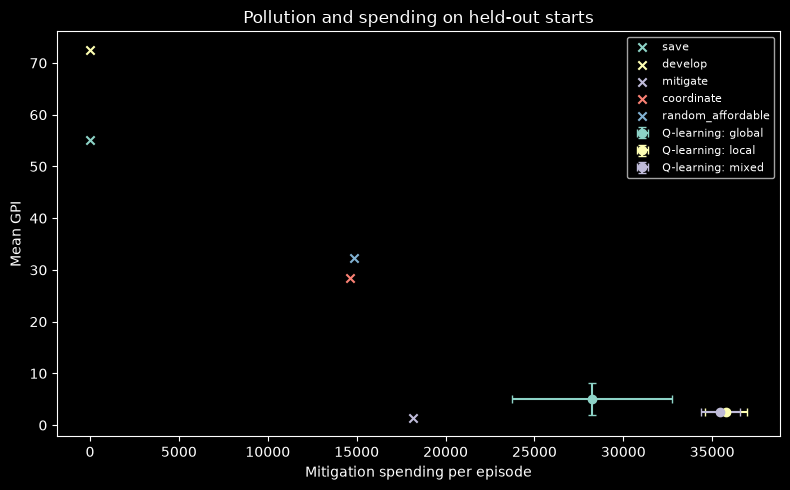

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))

for policy, row in learned_summary.iterrows():
    ax.errorbar(
        row["mitigation_spending"], row["mean_gpi"],
        xerr=row["spending_sd"], yerr=row["gpi_sd"],
        fmt="o", capsize=3, label=f"Q-learning: {policy}",
    )

for policy, row in baseline_summary.iterrows():
    ax.scatter(row["mitigation_spending"], row["mean_gpi"], marker="x", label=policy)

ax.set(
    xlabel="Mitigation spending per episode",
    ylabel="Mean GPI",
    title="Pollution and spending on held-out starts",
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{RESULTS_DIRECTORY}/images/pollution_vs_spending.svg")
plt.show()

- Local and mixed Q-learning reach low average GPI (2.60 and 2.57), with higher mitigation spending than global Q-learning.
- Global Q-learning spends less, but its mean GPI is higher (5.05) and varies more across training seeds.
- Fixed mitigation has the lowest GPI (1.36) and lower spending than the learned policies, but produces no economic development.
- Random affordable reaches EDI 100, but its mean GPI (32.29) is much higher than the learned policies' values.

The figure shows pollution and spending; the tables also show development and failure. These synthetic results do not establish one best policy.